# Biomomentum preprocessing with optional PID steady-force segmentation

Read each TXT file in `data/Biomomentum_Data/txts/`. Set `ENABLE_STEADY_STATE_SEGMENTATION = True` (default) to export only the detected steady-force interval, or `False` to export the full recording, including loading and settling. Run all cells in the **Dataprocess** environment with NumPy, pandas, Matplotlib, and IPython. Existing CSV files with matching names in `data/Biomomentum_Data/` are overwritten by the export cell.

Every output has exactly three ordered columns: **`Time, s`**, **`Indentation Position, mm`**, and **`Indentation Force, N`**. Use `Position (z), mm` as indentation and invert `Fz, N` so compression is positive. Reset **time only** to zero at the first retained sample; retain measured displacement and force, including PID oscillations. Do not filter, resample, or independently zero either measured signal.

A steady PID force can oscillate around its holding level. Detect the holding regime using a multi-period window mean and regression trend, with a separate allowance for force variation. Keep every sample within one continuous selected interval, including oscillation peaks and troughs. Review the plots before export. `_steady_state_manifest.csv` records the selected mode and original export boundaries, plus holding forces and detection settings when segmentation is enabled. Raw TXT files are read only.

In [10]:
import csv
import math
import sys

import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from pathlib import Path

def find_project_root(start):
    # Support running from the project root, data_process, or this notebook directory.
    for candidate in (start, *start.parents):
        if (candidate / 'data' / 'Biomomentum_Data' / 'txts').is_dir():
            return candidate
    raise FileNotFoundError('Could not find data/Biomomentum_Data/txts. Start the notebook within the project.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
INPUT_DIR = PROJECT_ROOT / 'data' / 'Biomomentum_Data' / 'txts'
OUTPUT_DIR = PROJECT_ROOT / 'data' / 'Biomomentum_Data'
sys.path.insert(0, str(PROJECT_ROOT / 'data_process' / 'utils'))
from creep_force_preprocessing import segment_force_steady_state, extract_indentation_cycles

SAMPLING_HZ = 200.0
ENABLE_STEADY_STATE_SEGMENTATION = False  # False keeps the full recording.
PID_STEADY_STATE_SETTINGS = dict(
    stability_window_s=2.0, stable_confirm_s=1.0, plateau_tail_s=5.0,
    level_tolerance_fraction=0.02, stable_std_fraction=0.05,
    stable_slope_fraction=0.01, release_guard_s=0.0, min_force_n=0.2,
)

EXTRACT_COLUMNS = [
    'Time, s',
    'Position (z), mm',
    'Fz, N',
]

EXTRACT_COLUMNS_SIGNS = [
    1.0,
    1.0,
    -1.0,
]

OUTPUT_COLUMNS = [
    'Time, s',
    'Indentation Position, mm',
    'Indentation Force, N',
]

if len(EXTRACT_COLUMNS) != len(OUTPUT_COLUMNS):
    raise ValueError(f'EXTRACT_COLUMNS and OUTPUT_COLUMNS must have the same length. '
                     f'Found {len(EXTRACT_COLUMNS)} and {len(OUTPUT_COLUMNS)}.')

if len(EXTRACT_COLUMNS_SIGNS) != len(EXTRACT_COLUMNS):
    raise ValueError('EXTRACT_COLUMNS_SIGNS must contain one sign per extracted column.')
if any(not math.isfinite(sign) or sign not in (-1.0, 1.0) for sign in EXTRACT_COLUMNS_SIGNS):
    raise ValueError('Extraction signs must be finite and equal to +1 or -1.')
if EXTRACT_COLUMNS_SIGNS[0] != 1.0:
    raise ValueError('Keep the time sign at +1 so timestamps remain increasing.')

print(f'Input directory: {INPUT_DIR}')
print(f'Output directory: {OUTPUT_DIR}')
print(f'Steady-state segmentation: {ENABLE_STEADY_STATE_SEGMENTATION}')

Input directory: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data/txts
Output directory: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data
Steady-state segmentation: False


## Read data sections

Extract only the selected columns between `<DATA>` and `<END DATA>`, using the column names rather than axis order. Validate finite numeric values before applying the configured signs. Preserve all selected measurements for segmentation and comparison plots.

In [11]:
def read_biomomentum_txt(txt_path):
    txt_path = Path(txt_path)
    rows = []
    in_data = False
    header = None
    block_rows = 0

    def invalid(line_number, message):
        return ValueError(f'{txt_path.name}:{line_number}: {message}')

    with txt_path.open('r', encoding='utf-8-sig', newline='') as handle:
        for line_number, fields in enumerate(csv.reader(handle, delimiter='\t'), start=1):
            fields = [field.strip() for field in fields]
            if not fields or not any(fields):
                continue
            marker = fields[0]
            if marker == '<DATA>':
                if in_data:
                    raise invalid(line_number, 'The previous data section is missing <END DATA>.')
                in_data, header, block_rows = True, None, 0
                continue
            if not in_data:
                continue
            if marker == '<END DATA>':
                if header is None or block_rows == 0:
                    raise invalid(line_number, 'The data section is empty.')
                in_data = False
                continue
            if header is None:
                header = fields
                missing = [column for column in EXTRACT_COLUMNS if column not in header]
                if missing:
                    raise invalid(line_number, f'Missing columns: {missing}')
                if len(header) != len(set(header)):
                    raise invalid(line_number, 'The header contains duplicate column names.')
                column_indices = [header.index(column) for column in EXTRACT_COLUMNS]
                continue
            if len(fields) != len(header):
                raise invalid(line_number, f'Expected {len(header)} columns, found {len(fields)}.')
            selected = [fields[index] for index in column_indices]
            for column, value in zip(EXTRACT_COLUMNS, selected):
                try:
                    numeric_value = float(value)
                except ValueError as exc:
                    raise invalid(line_number, f'{column} contains a nonnumeric value: {value!r}') from exc
                if not math.isfinite(numeric_value):
                    raise invalid(line_number, f'{column} contains a nonfinite value: {value!r}')
            rows.append(selected)
            block_rows += 1

    if in_data:
        raise ValueError(f'{txt_path.name}: Reached the end of the file without finding <END DATA>.')
    if not rows:
        raise ValueError(f'{txt_path.name}: No valid <DATA> section was found.')
    
    for row in rows:
        for column, sign, value in zip(EXTRACT_COLUMNS, EXTRACT_COLUMNS_SIGNS, row):
            numeric_value = float(value)
            numeric_value *= sign
            row[EXTRACT_COLUMNS.index(column)] = numeric_value
    return rows

## Validate all input files

Read every TXT before selecting intervals or writing CSVs. Each recording is treated as one loading-and-hold interval. Require continuous 200 Hz timestamps; multiple concatenated data blocks with restarted times or missing samples raise an error instead of being joined into a false continuous record.

In [12]:
txt_files = sorted(
    path for path in INPUT_DIR.iterdir()
    if path.is_file() and path.suffix.lower() == '.txt'
)
if not txt_files:
    raise FileNotFoundError(f'No TXT files were found in the input directory: {INPUT_DIR}')

# Validate all inputs before writing to avoid partial updates caused by malformed TXT files.
extracted = [(path, read_biomomentum_txt(path)) for path in txt_files]

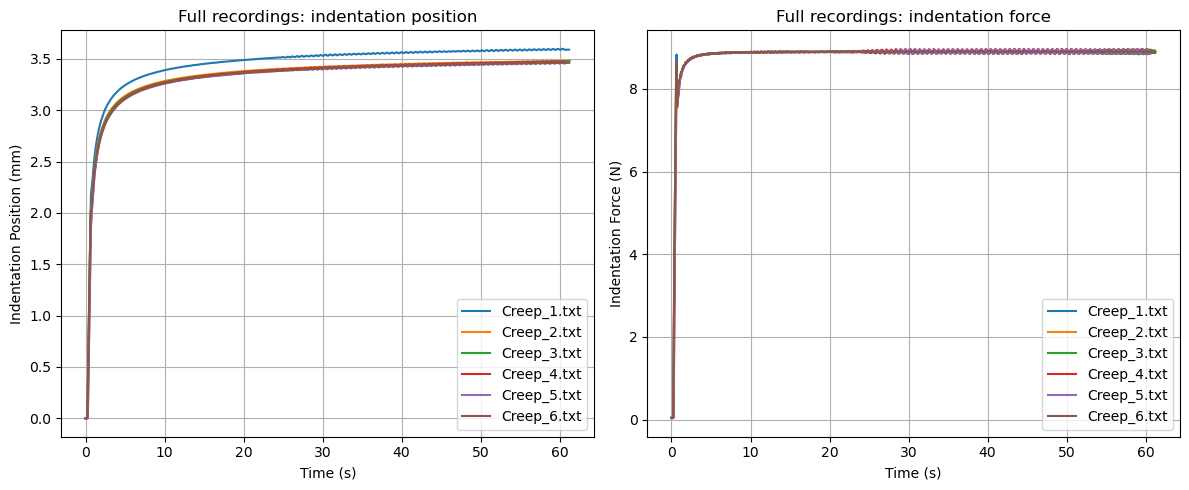

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for file, data in extracted:
    time = [float(row[0]) for row in data]
    position = [float(row[1]) for row in data]
    force = [float(row[2]) for row in data]

    axes[0].plot(time, position, label=file.name)
    axes[1].plot(time, force, label=file.name)

# Position subplot
axes[0].set_title('Full recordings: indentation position')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Indentation Position (mm)')
axes[0].legend()
axes[0].grid(True)

# Force subplot
axes[1].set_title('Full recordings: indentation force')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Indentation Force (N)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()
plt.close(fig)

## Select the export interval

With `ENABLE_STEADY_STATE_SEGMENTATION = False`, retain every sample from the first through the last timestamp. Skip PID detection, its settings, and the steady-force diagnostic plot. Continuous 200 Hz timestamps and finite sensor values are still required.

With `ENABLE_STEADY_STATE_SEGMENTATION = True`, apply the following PID steady-force selection.

Estimate the holding force from the median of the last **5 s**. Over a full trailing **2 s** window, require the mean within **2%** of that level, a force standard deviation no greater than **5%** of the level, and an absolute regression slope no greater than **1% of the holding force per second**. The 2 s window spans several of the approximately 0.6 s PID oscillations in these recordings; the variation allowance does not require a flat instantaneous force. Adjust `PID_STEADY_STATE_SETTINGS` if the controller oscillation period or amplitude changes.

Confirm the conditions continuously for **1 s**, and start at the first qualifying window endpoint in that run. Retain one continuous interval through the recording end, or stop earlier at the beginning of a later sustained loss of stability. Brief fluctuations and all bounded oscillation samples remain. No pointwise force threshold is applied to exported rows. These TXT recordings contain no release segment, so `release_guard_s` is zero; if future recordings include unloading, bound the hold before applying this detector.

The rolling statistics select boundaries only. Force and displacement remain unchanged, with their original alignment and amplitude. A recording without a confirmed steady interval raises an error before any exports are written.

In [14]:
segment_label = 'steady-force' if ENABLE_STEADY_STATE_SEGMENTATION else 'full-recording'
steady_extracted = []
segmentation_results = []
manifest_rows = []
for txt_path, rows in extracted:
    values = np.asarray(rows, dtype=float)
    sync = pd.DataFrame({
        'time_s': values[:, 0],
        'displacement_mm': values[:, 1],
        'force_n': values[:, 2],
    })
    cycle = pd.DataFrame([{
        'cycle': 1, 'onset_s': values[0, 0],
        'release_s': values[-1, 0] + 1.0 / SAMPLING_HZ,
    }])
    try:
        bounds = (segment_force_steady_state(sync, cycle, **PID_STEADY_STATE_SETTINGS)
                  if ENABLE_STEADY_STATE_SEGMENTATION else cycle)
        _, frame = extract_indentation_cycles(
            sync, bounds, sampling_hz=SAMPLING_HZ,
            steady_only=ENABLE_STEADY_STATE_SEGMENTATION,
        )[0]
    except ValueError as exc:
        raise ValueError(f'{txt_path.name}: {exc}') from exc
    event = bounds.iloc[0]
    steady_extracted.append((txt_path, frame))
    segmentation_results.append(dict(path=txt_path, sync=sync, bounds=bounds, frame=frame))
    manifest_rows.append({
        'file': f'{txt_path.stem}.csv',
        'source_txt': str(txt_path.relative_to(PROJECT_ROOT)),
        'steady_state_segmentation': ENABLE_STEADY_STATE_SEGMENTATION,
        'export_scope': 'steady_force_only' if ENABLE_STEADY_STATE_SEGMENTATION else 'full_load',
        'export_start_s': event.steady_start_s if ENABLE_STEADY_STATE_SEGMENTATION else event.onset_s,
        'export_end_s': event.steady_end_s if ENABLE_STEADY_STATE_SEGMENTATION else event.release_s,
        'original_start_s': values[0, 0], 'original_last_sample_s': values[-1, 0],
        'rows': len(frame), 'duration_s': frame[OUTPUT_COLUMNS[0]].iloc[-1],
        'sampling_hz': SAMPLING_HZ,
        'force_std_n': frame[OUTPUT_COLUMNS[2]].std(ddof=0),
        'force_peak_to_peak_n': np.ptp(frame[OUTPUT_COLUMNS[2]].to_numpy()),
        'position_sign': EXTRACT_COLUMNS_SIGNS[1], 'force_sign': EXTRACT_COLUMNS_SIGNS[2],
        **({
            'steady_start_s': event.steady_start_s, 'steady_end_s': event.steady_end_s,
            'steady_force_n': event.steady_force_n,
            **{f'pid_{key}': value for key, value in PID_STEADY_STATE_SETTINGS.items()},
        } if ENABLE_STEADY_STATE_SEGMENTATION else {}),
    })

steady_summary = pd.DataFrame(manifest_rows)
display(steady_summary[['file', 'export_scope', 'export_start_s', 'export_end_s',
                        'force_std_n', 'rows', 'duration_s']])

,file,export_scope,export_start_s,export_end_s,force_std_n,rows,duration_s
0,Creep_1.csv,full_load,0.0,61.2,0.666767,12240,61.195
1,Creep_2.csv,full_load,0.0,61.3,0.652180,12260,61.295
2,Creep_3.csv,full_load,0.0,61.2,0.658794,12240,61.195
3,Creep_4.csv,full_load,0.0,60.7,0.714708,12140,60.695
4,Creep_5.csv,full_load,0.0,60.7,0.711654,12140,60.695
5,Creep_6.csv,full_load,0.0,61.2,0.650693,12240,61.195


In [15]:
if ENABLE_STEADY_STATE_SEGMENTATION:
    ncols = min(3, len(segmentation_results))
    nrows = math.ceil(len(segmentation_results) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.4 * nrows), squeeze=False)
    for axis, result in zip(axes.flat, segmentation_results):
        sync = result['sync']
        event = result['bounds'].iloc[0]
        dt = float(np.median(np.diff(sync.time_s)))
        window = max(3, int(np.ceil(PID_STEADY_STATE_SETTINGS['stability_window_s'] / dt)))
        force_mean = sync.force_n.rolling(window, min_periods=window).mean()
        view_end = min(event.steady_end_s, event.steady_start_s + 4.0)
        view = sync.time_s <= view_end
        axis.plot(sync.loc[view, 'time_s'], sync.loc[view, 'force_n'], lw=0.8,
                  color='tab:blue', label='Measured force')
        axis.plot(sync.loc[view, 'time_s'], force_mean[view], lw=1.2,
                  color='tab:red', label='Window mean (detection only)')
        level = event.steady_force_n
        tolerance = PID_STEADY_STATE_SETTINGS['level_tolerance_fraction'] * level
        axis.axhspan(level - tolerance, level + tolerance, color='tab:orange', alpha=0.15)
        axis.axvspan(event.steady_start_s, view_end, color='tab:green', alpha=0.12)
        axis.axvline(event.steady_start_s, color='tab:green', ls='--', lw=1)
        axis.set(title=f"{result['path'].stem}: steady start {event.steady_start_s:.3f} s",
                 xlabel='Original time (s)', ylabel='Indentation force (N)')
        axis.grid(True, alpha=0.25)
    axes.flat[0].legend(fontsize=8)
    for axis in list(axes.flat)[len(segmentation_results):]:
        axis.set_visible(False)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## Inspect retained force and displacement

The comparison below uses only the selected intervals, with time zero at the first retained sample in either mode. Force oscillations are intentionally visible and preserved. No displacement offset is removed, and position and force always retain the same sample count and timestamps.

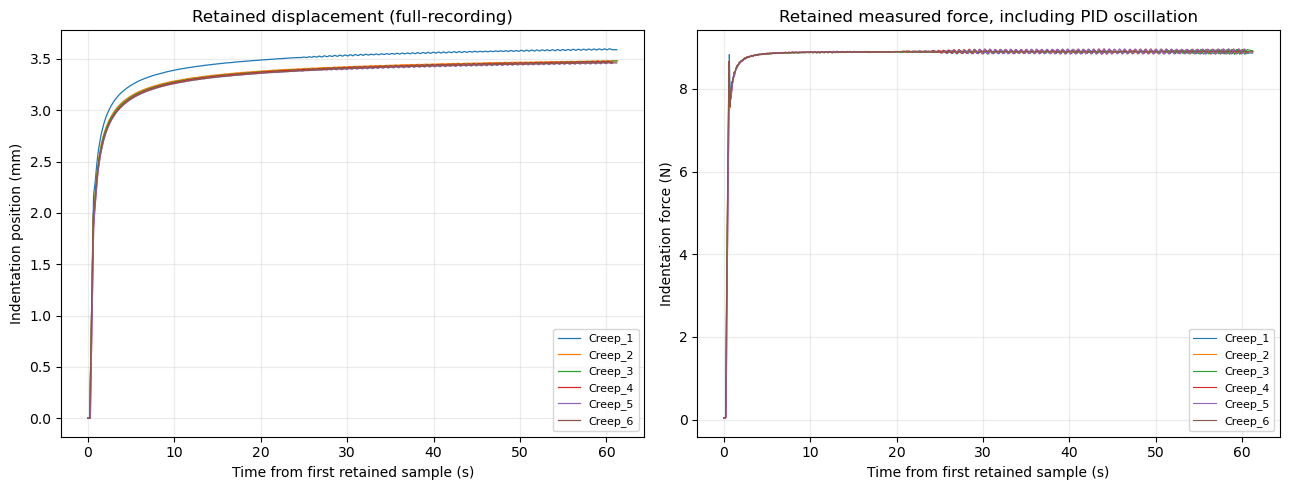

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for txt_path, frame in steady_extracted:
    time = frame[OUTPUT_COLUMNS[0]]
    line, = axes[0].plot(time, frame[OUTPUT_COLUMNS[1]], lw=0.9, label=txt_path.stem)
    axes[1].plot(time, frame[OUTPUT_COLUMNS[2]], lw=0.8, color=line.get_color(), label=txt_path.stem)
axes[0].set(title=f'Retained displacement ({segment_label})', ylabel='Indentation position (mm)')
axes[1].set(title='Retained measured force, including PID oscillation', ylabel='Indentation force (N)')
for axis in axes:
    axis.set_xlabel('Time from first retained sample (s)')
    axis.grid(True, alpha=0.25)
    axis.legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

## Export selected intervals

All inputs and selected intervals are validated before writing. Each CSV contains exactly the three configured columns without a row index. Running this cell overwrites matching exports and writes `_steady_state_manifest.csv` with the selected mode, original export boundaries (end exclusive), measured variation, and sampling rate. Holding force and PID detection settings are recorded only when segmentation is enabled. Raw TXT measurements remain untouched.

Steady-only exports start under load. A downstream model that assumes an unloaded initial reference or relaxed viscoelastic states must account for the preceding load history before using these steady-only exports.

In [17]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
export_summary = []
for txt_path, frame in steady_extracted:
    csv_path = OUTPUT_DIR / f'{txt_path.stem}.csv'
    with csv_path.open('w', encoding='utf-8', newline='') as handle:
        writer = csv.writer(handle, lineterminator='\n')
        writer.writerow(OUTPUT_COLUMNS)
        writer.writerows(frame.itertuples(index=False, name=None))
    export_summary.append({'file': csv_path.name, 'rows': len(frame), 'columns': len(OUTPUT_COLUMNS)})
    print(f'{txt_path.name} -> {csv_path.name}: {len(frame):,} {segment_label} rows x {len(OUTPUT_COLUMNS)} columns')

manifest_path = OUTPUT_DIR / '_steady_state_manifest.csv'
steady_summary.to_csv(manifest_path, index=False)
print(f'\nDone: exported {len(export_summary)} {segment_label} CSV files to {OUTPUT_DIR}')
print(f'Segmentation metadata: {manifest_path.name}')

Creep_1.txt -> Creep_1.csv: 12,240 full-recording rows x 3 columns
Creep_2.txt -> Creep_2.csv: 12,260 full-recording rows x 3 columns
Creep_3.txt -> Creep_3.csv: 12,240 full-recording rows x 3 columns
Creep_4.txt -> Creep_4.csv: 12,140 full-recording rows x 3 columns
Creep_5.txt -> Creep_5.csv: 12,140 full-recording rows x 3 columns
Creep_6.txt -> Creep_6.csv: 12,240 full-recording rows x 3 columns

Done: exported 6 full-recording CSV files to /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Biomomentum_Data
Segmentation metadata: _steady_state_manifest.csv


## Preview the first 5 rows of the first CSV

In [18]:
preview_path = OUTPUT_DIR / export_summary[0]['file']
with preview_path.open('r', encoding='utf-8', newline='') as handle:
    reader = csv.reader(handle)
    preview_header = next(reader)
    print(' | '.join(preview_header))
    for _, row in zip(range(5), reader):
        print(' | '.join(row))

Time, s | Indentation Position, mm | Indentation Force, N
0.0 | 4.60787e-12 | 0.038148
0.005 | 4.60787e-12 | 0.038148
0.01 | 4.60787e-12 | 0.038148
0.015 | 4.60787e-12 | 0.038148
0.02 | 4.60787e-12 | 0.038148
